# 03 · Transfer learning con extracción de features (Keras, CPU)

**Idea:** en vez de entrenar una CNN desde cero, se usa una red preentrenada en ImageNet (MobileNetV3-Small) como extractor de características. Cada imagen pasa **una sola vez** por la red, que permanece congelada; se guarda el vector resultante (576 números por imagen) y se entrena únicamente una cabeza pequeña sobre esos vectores. Entrenar la cabeza tarda segundos, así que se puede usar la resolución de entrada completa (224x224) aun sin GPU.

**Punto de partida (notebook 02):** el baseline sin pesos alcanzó accuracy 0,803 y F1 macro 0,746; con `class_weight` balanceado, 0,758 y 0,723, es decir, los pesos completos no ayudaron en el agregado. Por eso aquí se comparan dos configuraciones: sin pesos (`CW_POWER=0`) y con pesos suaves (`CW_POWER=0.5`). Los errores típicos del baseline eran ácaros → `Target_Spot`, `Black_rot` ↔ `Esca` en uva y confusiones entre cultivos distintos.

**Experimentos:** se corrieron cuatro configuraciones (25 % o 100 % de train, con `CW_POWER` de 0 o 0,5). Las salidas de este notebook (curvas, métricas por clase y confusiones) corresponden a la configuración final: **todo el train y `CW_POWER=0.5`**. La tabla de la sección 9 compara las cuatro.

**Limitación:** como el backbone está congelado y las features se calculan una sola vez, esta versión no usa data augmentation.

## 1. Setup

In [1]:
import os
import sys
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

from src.data import load_splits
from src.features import build_backbone, extract_features

SEED = 42
keras.utils.set_random_seed(SEED)
plt.rcParams["figure.dpi"] = 110
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Configuración

- `BACKBONE` e `IMG_SIZE`: red preentrenada (MobileNetV3-Small; también está soportada `efficientnetb0`) y resolución de entrada (224x224).
- `BATCH_FEAT`: tamaño del lote al extraer features. `BATCH_HEAD` y `EPOCHS`: tamaño del lote y máximo de épocas al entrenar la cabeza.
- `USE_SUBSET`: con `True`, la cabeza se entrena con el **mismo 25 % de train que usó el baseline** (misma semilla y estratificación), para una comparación justa; con `False`, con todo train. La extracción de features se hace siempre sobre todo el dataset, así que esta opción no cambia el tiempo de extracción.
- `CW_POWER`: exponente aplicado a los pesos de clase balanceados: `0` = sin pesos, `0.5` = pesos suaves, `1` = pesos balanceados completos.
- Configuración de los resultados mostrados en este notebook: `USE_SUBSET=False` y `CW_POWER=0.5`.

In [2]:
BACKBONE = "mobilenetv3small"   # opciones: "mobilenetv3small" | "efficientnetb0"
IMG_SIZE = (224, 224)           # (ancho, alto)
BATCH_FEAT = 64                 # lote para extraer features

USE_SUBSET = False              # True: mismo 25 % de train que el baseline | False: todo train
SUBSET_FRACTION = 0.25
CW_POWER = 0.5                 # 0 = sin pesos | 0.5 = suaves | 1 = balanceados

EPOCHS = 40
BATCH_HEAD = 128

EXP_NAME = (
    f"tl_{BACKBONE}_{IMG_SIZE[0]}_cw{CW_POWER}"
    + ("_subset" if USE_SUBSET else "_full")
)
print("Experimento:", EXP_NAME)

Experimento: tl_mobilenetv3small_224_cw0.5_full


## 3. Datos y backbone

Se cargan los mismos splits que en los notebooks anteriores y se crea MobileNetV3-Small preentrenada en ImageNet, sin su capa final de clasificación y con pooling global: cada imagen se resume en un vector de 576 números. El backbone se mantiene congelado (sus 939.120 parámetros no se entrenan).

In [3]:
train, val, test = load_splits()

label_feat = train.features["label"]
id2name = dict(enumerate(label_feat.names))
n_classes = len(id2name)
names = [id2name[i] for i in range(n_classes)]
bg_id = [k for k, v in id2name.items() if v.startswith("Background")][0]
print("Clases:", n_classes, "| train/val/test:", len(train), len(val), len(test))

backbone = build_backbone(BACKBONE, IMG_SIZE)
backbone.trainable = False
print("Backbone:", backbone.name, "| params:", f"{backbone.count_params():,}",
      "| dim. de features:", backbone.output_shape[-1])

AVISO: el dataset no trae leaf_id; se usa un split estratificado por clase. Puede haber fuga entre imágenes de una misma hoja, por lo que las métricas pueden ser algo optimistas.
Clases: 39 | train/val/test: 38812 8317 8318
Backbone: MobileNetV3Small | params: 939,120 | dim. de features: 576


## 4. Extracción de features

Es la parte lenta del notebook, pero **se hace una sola vez**: el resultado se guarda en `data/cache/` y las ejecuciones siguientes lo leen del disco (por eso el tiempo de extracción que se ve aquí es casi cero). Durante la primera extracción se imprimen el progreso, las imágenes por segundo y el tiempo restante estimado. Si el proceso se interrumpe, esa extracción empieza de cero. Las features se calculan sin data augmentation.

In [4]:
t0 = time.time()
X_train, y_train = extract_features(train, backbone, IMG_SIZE, name="train", batch_size=BATCH_FEAT)
X_val, y_val = extract_features(val, backbone, IMG_SIZE, name="val", batch_size=BATCH_FEAT)
X_test, y_test = extract_features(test, backbone, IMG_SIZE, name="test", batch_size=BATCH_FEAT)
print(f"Extracción total: {(time.time() - t0) / 60:.1f} min")
print("train:", X_train.shape, "| val:", X_val.shape, "| test:", X_test.shape)

[cache] feat_train_MobileNetV3Small_38812_224x224.npz
[cache] feat_val_MobileNetV3Small_8317_224x224.npz
[cache] feat_test_MobileNetV3Small_8318_224x224.npz
Extracción total: 0.0 min
train: (38812, 576) | val: (8317, 576) | test: (8318, 576)


In [5]:
if USE_SUBSET:
    idx = np.arange(len(y_train))
    keep, _ = train_test_split(
        idx, train_size=SUBSET_FRACTION, stratify=y_train, random_state=SEED
    )
    X_fit, y_fit = X_train[keep], y_train[keep]
    print("Train de la cabeza (mismo subconjunto que el baseline):", X_fit.shape)
else:
    X_fit, y_fit = X_train, y_train
    print("Train de la cabeza (completo):", X_fit.shape)

Train de la cabeza (completo): (38812, 576)


## 5. Pesos de clase (opcional)

Los pesos balanceados de scikit-learn se elevan al exponente `CW_POWER`. Con `0.5` se suavizan: las clases chicas pesan menos que con el balanceo completo (aquí los pesos van de 0,51 a 3,06; con `CW_POWER=1` irían de 0,26 a 9,4 aproximadamente). Con `CW_POWER=0` no se usan pesos.

In [6]:
classes = np.arange(n_classes)
balanced = compute_class_weight("balanced", classes=classes, y=y_fit)
weights = balanced ** CW_POWER
class_weight = {int(c): float(w) for c, w in zip(classes, weights)} if CW_POWER > 0 else None
print("CW_POWER =", CW_POWER, "| pesos min/max:", round(weights.min(), 2), "/", round(weights.max(), 2))

CW_POWER = 0.5 | pesos min/max: 0.51 / 3.06


## 6. Cabeza de clasificación

Recibe el vector de 576 features y lo normaliza (con la media y el desvío de train); luego aplica dropout de 0,2, una capa densa de 256 unidades con ReLU, dropout de 0,3 y una capa final de 39 salidas con softmax. Tiene 158.888 parámetros (incluidos los de la normalización), contra 103.191 del baseline.

In [7]:
norm = layers.Normalization()
norm.adapt(X_fit)

def build_head(input_dim, n_classes):
    inputs = keras.Input(shape=(input_dim,))
    x = norm(inputs)
    x = layers.Dropout(0.2)(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(n_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="head")

head = build_head(X_fit.shape[1], n_classes)
head.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
head.summary()

Model: "head"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, 576)            │         1,153 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       147,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 39)             │        10,023 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 158,888 (620.66 KB)

 Trainable params: 157,735 (616.15 KB)

 Non-trainable params: 1,153 (4.51 KB)

## 7. Entrenamiento de la cabeza

Optimizador Adam (tasa de aprendizaje inicial de 1e-3), lotes de 128 y hasta 40 épocas, con `EarlyStopping` (paciencia de 6 épocas sobre `val_loss`) y `ReduceLROnPlateau` (reduce a la mitad la tasa de aprendizaje si no mejora en 3 épocas). En la configuración final el entrenamiento tarda unos 30 segundos y completa las 40 épocas: `EarlyStopping` no se activó y la `val_loss` seguía bajando levemente en la última época, por lo que un máximo mayor de épocas podría dar una mejora pequeña.

In [8]:
os.makedirs(os.path.join(ROOT, "models"), exist_ok=True)
os.makedirs(os.path.join(ROOT, "reports"), exist_ok=True)

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
]

t0 = time.time()
history = head.fit(
    X_fit, y_fit,
    validation_data=(X_val, y_val),
    batch_size=BATCH_HEAD,
    epochs=EPOCHS,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=2,
)
train_time = time.time() - t0
print(f"Entrenamiento de la cabeza: {train_time:.0f} s")

Epoch 1/40
304/304 - 1s - 5ms/step - accuracy: 0.8408 - loss: 0.5926 - val_accuracy: 0.9585 - val_loss: 0.1349 - learning_rate: 0.0010
Epoch 2/40
304/304 - 1s - 2ms/step - accuracy: 0.9422 - loss: 0.1873 - val_accuracy: 0.9681 - val_loss: 0.0954 - learning_rate: 0.0010
Epoch 3/40
304/304 - 1s - 2ms/step - accuracy: 0.9558 - loss: 0.1349 - val_accuracy: 0.9751 - val_loss: 0.0768 - learning_rate: 0.0010
Epoch 4/40
304/304 - 1s - 2ms/step - accuracy: 0.9645 - loss: 0.1089 - val_accuracy: 0.9780 - val_loss: 0.0688 - learning_rate: 0.0010
Epoch 5/40
304/304 - 1s - 2ms/step - accuracy: 0.9694 - loss: 0.0936 - val_accuracy: 0.9781 - val_loss: 0.0652 - learning_rate: 0.0010
Epoch 6/40
304/304 - 1s - 2ms/step - accuracy: 0.9725 - loss: 0.0831 - val_accuracy: 0.9800 - val_loss: 0.0617 - learning_rate: 0.0010
Epoch 7/40
304/304 - 1s - 2ms/step - accuracy: 0.9745 - loss: 0.0751 - val_accuracy: 0.9779 - val_loss: 0.0679 - learning_rate: 0.0010
Epoch 8/40
304/304 - 1s - 2ms/step - accuracy: 0.9751 -

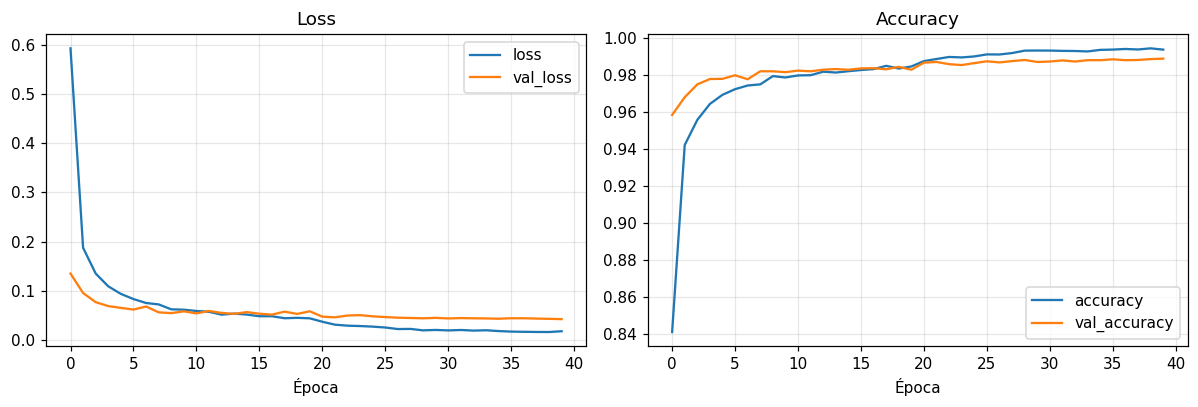

In [9]:
hist = pd.DataFrame(history.history)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
hist[["loss", "val_loss"]].plot(ax=axes[0], title="Loss")
hist[["accuracy", "val_accuracy"]].plot(ax=axes[1], title="Accuracy")
for ax in axes:
    ax.set_xlabel("Época")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Evaluación en test

Las métricas son las mismas que en el baseline: accuracy, F1 macro (métrica principal) y F1 macro sin la clase fondo. Con la configuración final, el modelo alcanza accuracy 0,987 y F1 macro 0,982. Debajo se muestran las diez clases con peor F1 y el gráfico de F1 por clase.

In [10]:
probs = head.predict(X_test, batch_size=256, verbose=0)
y_pred = probs.argmax(axis=1)

acc = float((y_pred == y_test).mean())
f1_macro = f1_score(y_test, y_pred, average="macro")
labels_no_bg = [c for c in range(n_classes) if c != bg_id]
f1_macro_no_bg = f1_score(y_test, y_pred, labels=labels_no_bg, average="macro")

print(f"Accuracy:                     {acc:.4f}")
print(f"F1 macro:                     {f1_macro:.4f}")
print(f"F1 macro (sin clase fondo):   {f1_macro_no_bg:.4f}")

Accuracy:                     0.9870
F1 macro:                     0.9818
F1 macro (sin clase fondo):   0.9815


In [11]:
report = classification_report(
    y_test, y_pred, labels=list(range(n_classes)),
    target_names=names, zero_division=0, output_dict=True,
)
df_rep = pd.DataFrame(report).T.iloc[:n_classes][["precision", "recall", "f1-score", "support"]]
df_rep.sort_values("f1-score").head(10).round(3)

,precision,recall,f1-score,support
Corn___Cercospora_leaf_spot Gray_leaf_spot,0.905,0.870,0.887,77.0
Tomato___Target_Spot,0.947,0.924,0.935,211.0
Corn___Northern_Leaf_Blight,0.927,0.946,0.936,147.0
Potato___healthy,0.885,1.000,0.939,23.0
Tomato___Early_blight,0.965,0.920,0.942,150.0
Tomato___Spider_mites Two-spotted_spider_mite,0.938,0.960,0.949,252.0
Potato___Late_blight,0.967,0.967,0.967,150.0
Tomato___Leaf_Mold,0.965,0.972,0.969,143.0
Tomato___Late_blight,0.975,0.965,0.970,287.0
Tomato___Tomato_mosaic_virus,0.982,0.964,0.973,56.0


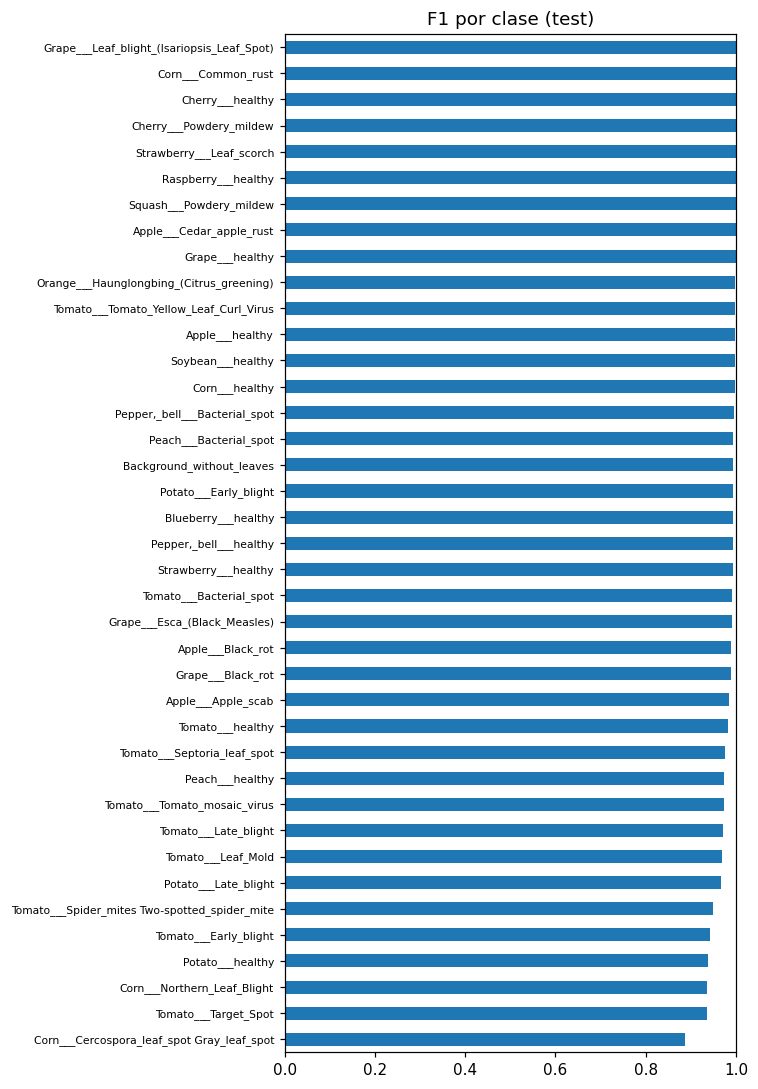

In [12]:
f1_by_class = df_rep["f1-score"].sort_values()
fig, ax = plt.subplots(figsize=(7, 10))
f1_by_class.plot.barh(ax=ax)
ax.set_xlim(0, 1)
ax.set_title("F1 por clase (test)")
ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

### 8.1 Confusiones

La tabla lista las 10 confusiones más frecuentes (clase real → clase predicha) y la matriz de confusión normalizada por fila muestra el panorama completo: la diagonal es la proporción de aciertos de cada clase y todo lo que queda fuera de ella son errores.

In [13]:
cm = confusion_matrix(y_test, y_pred, labels=list(range(n_classes)))
off = cm.copy()
np.fill_diagonal(off, 0)
pairs = [(off[i, j], names[i], names[j]) for i in range(n_classes) for j in range(n_classes) if off[i, j] > 0]
pairs.sort(reverse=True)
pd.DataFrame(pairs[:10], columns=["cantidad", "clase real", "predicha como"])

,cantidad,clase real,predicha como
0,10,Tomato___Target_Spot,Tomato___Spider_mites Two-spotted_spider_mite
1,9,Corn___Cercospora_leaf_spot Gray_leaf_spot,Corn___Northern_Leaf_Blight
2,7,Corn___Northern_Leaf_Blight,Corn___Cercospora_leaf_spot Gray_leaf_spot
3,5,Tomato___Spider_mites Two-spotted_spider_mite,Tomato___Target_Spot
4,5,Tomato___Late_blight,Potato___Late_blight
5,4,Tomato___Early_blight,Tomato___Septoria_leaf_spot
6,3,Tomato___Late_blight,Tomato___Early_blight
7,3,Peach___Bacterial_spot,Peach___healthy
8,2,Tomato___healthy,Tomato___Spider_mites Two-spotted_spider_mite
9,2,Tomato___Tomato_mosaic_virus,Tomato___Leaf_Mold


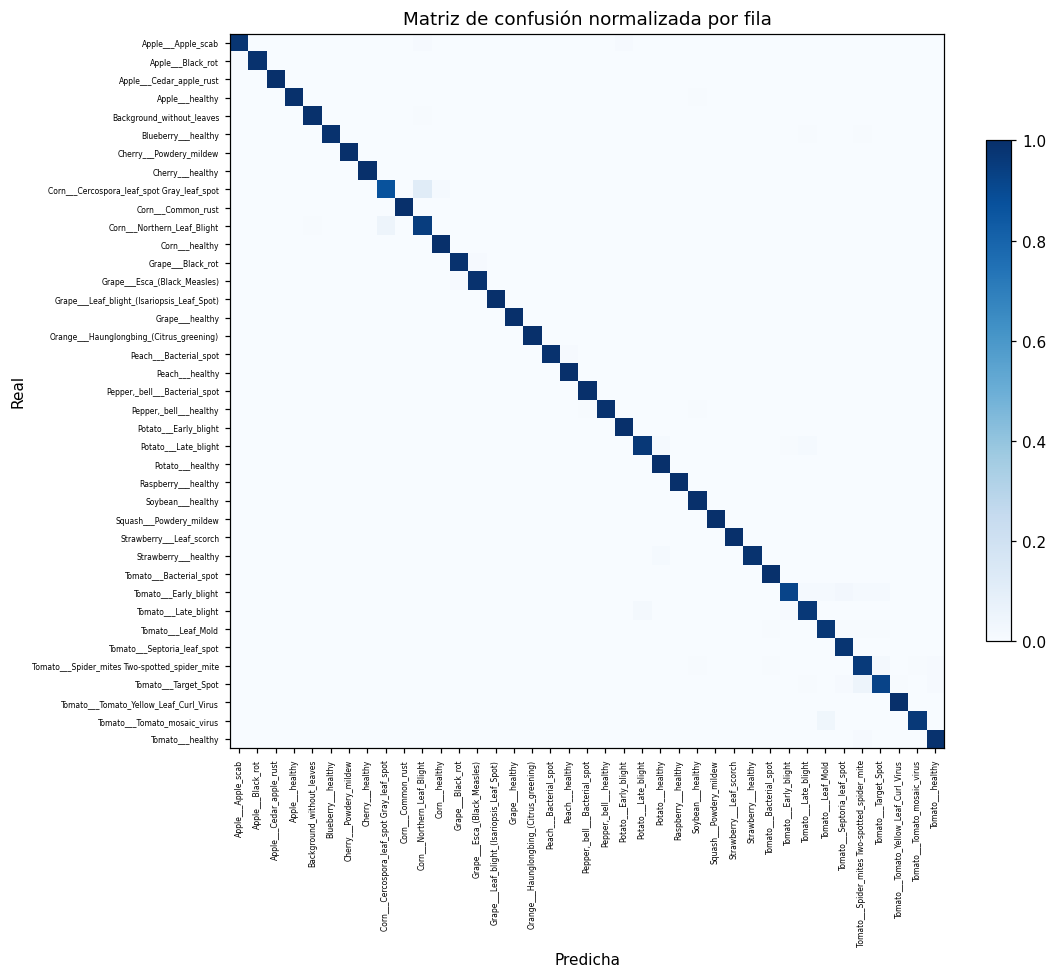

In [14]:
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(n_classes)); ax.set_yticks(range(n_classes))
ax.set_xticklabels(names, rotation=90, fontsize=5)
ax.set_yticklabels(names, fontsize=5)
ax.set_xlabel("Predicha"); ax.set_ylabel("Real")
ax.set_title("Matriz de confusión normalizada por fila")
plt.colorbar(im, fraction=0.03)
plt.tight_layout()
plt.show()

## 9. Guardar resultados y modelo completo

Se guardan los resultados del experimento en `reports/` y un modelo de punta a punta (imagen → backbone → cabeza) en `models/`, que usa el notebook 04 para Grad-CAM y la prueba de robustez. El archivo se llama `<experimento>_full.keras`; como el nombre del experimento sin subconjunto ya termina en `_full`, el de la configuración final queda como `tl_mobilenetv3small_224_cw0.5_full_full.keras`. La tabla final compara los experimentos de entrenamiento guardados, incluidos los del baseline (notebook 02).

In [15]:
results = {
    "experimento": EXP_NAME,
    "img_size": list(IMG_SIZE),
    "subset": USE_SUBSET,
    "class_weight": CW_POWER > 0,
    "epocas_corridas": int(len(hist)),
    "minutos_entrenamiento": round(train_time / 60, 1),
    "accuracy": round(acc, 4),
    "f1_macro": round(float(f1_macro), 4),
    "f1_macro_sin_fondo": round(float(f1_macro_no_bg), 4),
    "params": int(head.count_params()),
}
out = os.path.join(ROOT, "reports", f"{EXP_NAME}.json")
with open(out, "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)
print("Guardado en", out)

# Modelo completo: imagen (0-255) -> backbone -> cabeza
inp = keras.Input(shape=(IMG_SIZE[1], IMG_SIZE[0], 3))
full_model = keras.Model(inp, head(backbone(inp)), name=EXP_NAME)
full_model.save(os.path.join(ROOT, "models", f"{EXP_NAME}_full.keras"))
results

Guardado en c:\Users\Carlos\Desktop\Python-Prep\proyecto_vision_plantvillage\reports\tl_mobilenetv3small_224_cw0.5_full.json


{'experimento': 'tl_mobilenetv3small_224_cw0.5_full',
 'img_size': [224, 224],
 'subset': False,
 'class_weight': True,
 'epocas_corridas': 40,
 'minutos_entrenamiento': 0.5,
 'accuracy': 0.987,
 'f1_macro': 0.9818,
 'f1_macro_sin_fondo': 0.9815,
 'params': 158888}

In [16]:
# Comparación de los experimentos de entrenamiento guardados en reports/
rows = []
for fn in sorted(os.listdir(os.path.join(ROOT, "reports"))):
    if fn.endswith(".json"):
        with open(os.path.join(ROOT, "reports", fn), encoding="utf-8") as f:
            r = json.load(f)
        if "experimento" in r:  # se omiten otros reportes, como el de robustez
            rows.append(r)
pd.DataFrame(rows).set_index("experimento")[
    ["subset", "class_weight", "accuracy", "f1_macro", "f1_macro_sin_fondo", "minutos_entrenamiento", "params"]
]

,subset,class_weight,accuracy,f1_macro,f1_macro_sin_fondo,minutos_entrenamiento,params
experimento,,,,,,,
baseline_cw_128_subset,True,True,0.7580,0.7232,0.7233,20.0,103191
baseline_nocw_128_subset,True,False,0.8033,0.7458,0.7426,17.9,103191
tl_mobilenetv3small_224_cw0.0_full,False,False,0.9847,0.9800,0.9796,0.3,158888
tl_mobilenetv3small_224_cw0.0_subset,True,False,0.9675,0.9587,0.9579,0.1,158888
tl_mobilenetv3small_224_cw0.5_full,False,True,0.9870,0.9818,0.9815,0.5,158888
tl_mobilenetv3small_224_cw0.5_subset,True,True,0.9681,0.9598,0.9592,0.2,158888


## 10. Conclusiones

- **Mejora vs. baseline (mismo 25 % de train):** F1 macro 0,959 contra 0,746 del baseline (0,960 con pesos suaves) y accuracy 0,968 contra 0,803. Con la misma cantidad de datos, la peor clase pasó de F1 0,37 a 0,80 (corrida sin pesos).
- **Tiempo:** entrenar la cabeza tarda entre 6 y 30 segundos según la configuración, frente a unos 18 minutos del baseline. La extracción de features es el paso más lento, pero se hace una sola vez y queda en caché.
- **Ajuste (configuración final):** accuracy de train 0,994 contra 0,989 en validación. La `val_loss` baja hasta 0,042 y seguía mejorando levemente en la época 40. No hay sobreajuste marcado.
- **Errores que persisten (configuración final):** las clases más débiles son `Corn___Cercospora_leaf_spot` (F1 0,89), `Tomato___Target_Spot` (0,94) y `Corn___Northern_Leaf_Blight` (0,94). Las confusiones más frecuentes son `Target_Spot` → ácaros (10 casos) y `Cercospora` ↔ `Northern_Leaf_Blight` (9 y 7), casi todas entre enfermedades parecidas dentro de tomate o maíz. Ya no aparecen las confusiones entre cultivos distintos del baseline, salvo `Tomato___Late_blight` → `Potato___Late_blight` (5 casos), que es el mismo patógeno en dos cultivos.
- **Clase fondo:** el F1 macro sin ella (0,9815) es prácticamente igual al que la incluye (0,9818); no infla el resultado.
- **Subconjunto vs. completo:** con todo el train, el F1 macro sube de 0,959 a 0,980 sin pesos (accuracy 0,968 → 0,985) y de 0,960 a 0,982 con pesos suaves. Los datos aportan más que cualquier otro cambio probado.
- **Pesos de clase (`CW_POWER=0.5`):** +0,001 de F1 macro con el 25 % de train y +0,002 con train completo. Cada configuración se corrió una sola vez y la diferencia probablemente esté dentro del ruido, por lo que no se considera un efecto real.
- **Mejor configuración:** MobileNetV3-Small congelada, 224x224, train completo y `CW_POWER=0.5`: accuracy 0,987 y F1 macro 0,982.
- **Limitaciones:** sin data augmentation (las features se calculan una vez), backbone congelado, split sin agrupar por hoja (métricas probablemente optimistas), una sola corrida por configuración, y evaluación con imágenes del mismo tipo que las de entrenamiento (laboratorio, fondo uniforme).
- **Próximo paso:** el notebook 04 analiza en qué se fija el modelo con Grad-CAM y lo evalúa sobre imágenes de campo, que es la prueba de si estos resultados se sostienen fuera del laboratorio.